# Baseline final - Conditional VAE C-full

Este notebook entrena la version final del baseline CVAE para perfiles diarios de demanda electrica. La metodologia queda corregida respecto del primer baseline:

- split temporal con `train` / `val` / `test`;
- escalado de `X` y variables numericas de `C` ajustado solo con train;
- vector condicional `C-full` documentado y consistente con el codigo;
- seleccion del checkpoint por validation loss, no por test;
- early stopping y beta warm-up para controlar el colapso del KL;
- evaluacion separada de reconstruccion y generacion;
- repeticion con varias seeds y reporte de media/desvio.


In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import os
import sys

project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent
sys.path.append(str(project_root))

# Evita warnings de matplotlib cuando el home no es escribible.
os.environ.setdefault("MPLCONFIGDIR", str(project_root / ".matplotlib_cache"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import torch

from src.data_quality import load_daily_datasets
from src.cvae_preprocessing import prepare_cvae_datasets
from src.cvae_experiments import run_seed_experiments
from src.cvae_evaluation import summarize_seed_metrics
from src.cvae_training import (
    plot_loss_curves,
    plot_reconstruction_vs_real,
    plot_generated_vs_real_by_condition,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project root: {project_root}")
print(f"Device: {device}")


Matplotlib is building the font cache; this may take a moment.


Project root: /Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml
Device: cpu


## 1. Datos y preprocesamiento sin leakage

La preparacion se hace en este orden: cargar datos crudos, remover el outlier definido para el baseline, hacer split temporal y recien despues ajustar escaladores usando solo train.

Split temporal usado:

- `train`: 2021-2023
- `val`: 2024
- `test`: 2025-2026


In [2]:
x_profiles, conditions = load_daily_datasets(
    x_path=project_root / "x_perfiles_diarios.csv",
    c_path=project_root / "c_condiciones_diarias.csv",
)

prepared, preprocessing = prepare_cvae_datasets(
    x_profiles=x_profiles,
    conditions=conditions,
    train_end_year=2023,
    val_year=2024,
    test_start_year=2025,
    remove_outliers=True,
)

feature_names = preprocessing["condition_metadata"]["feature_names"]
print(f"C-full dimension: {len(feature_names)}")
pd.DataFrame({"feature": feature_names})


Fechas removidas: 1 (['2023-03-01'])
train: 1094 dias (2021-01-01 a 2023-12-31)
val: 366 dias (2024-01-01 a 2024-12-31)
test: 485 dias (2025-01-01 a 2026-04-30)
train: X (1094, 24) | C (1094, 21)
val: X (366, 24) | C (366, 21)
test: X (485, 24) | C (485, 21)
C-full dimension: 21


,feature
0,tipo_habil
1,tipo_sabado
2,tipo_domingo
3,tipo_feriado
4,mes_sin
5,mes_cos
6,dia_semana_sin
7,dia_semana_cos
8,es_feriado
9,temp_media


## 2. Configuracion del baseline

El baseline final usa `C-full`, arquitectura MLP simple y `beta=0.01` con warm-up. El valor de beta es deliberadamente menor que 1 porque en el baseline original el KL colapsaba a cero; esta version busca conservar uso del espacio latente sin destruir la reconstruccion.


In [3]:
SEEDS = [42, 123, 2024]

HYPERPARAMS = {
    "profile_dim": 24,
    "hidden_dim": 128,
    "latent_dim": 8,
    "batch_size": 64,
    "n_epochs": 300,
    "learning_rate": 1e-3,
    "beta": 0.01,
    "beta_warmup_epochs": 50,
    "patience": 35,
    "min_delta": 1e-5,
    "weight_decay": 1e-5,
}

HYPERPARAMS


{'profile_dim': 24,
 'hidden_dim': 128,
 'latent_dim': 8,
 'batch_size': 64,
 'n_epochs': 300,
 'learning_rate': 0.001,
 'beta': 0.01,
 'beta_warmup_epochs': 50,
 'patience': 35,
 'min_delta': 1e-05,
 'weight_decay': 1e-05}

## 3. Entrenamiento multi-seed

Cada seed entrena desde cero. El mejor checkpoint de cada corrida se elige con `val_total`; test queda reservado para la evaluacion final.


In [4]:
results = run_seed_experiments(
    prepared_data=prepared,
    preprocessing=preprocessing,
    seeds=SEEDS,
    hyperparams=HYPERPARAMS,
    device=device,
    verbose_every=50,
)



=== Seed 42 ===
Epoch 050 | beta 0.0100 | train 0.0167 (recon 0.0091, kl 0.7614) | val 0.0182 (recon 0.0107, kl 0.7448)
Epoch 100 | beta 0.0100 | train 0.0120 (recon 0.0065, kl 0.5549) | val 0.0138 (recon 0.0083, kl 0.5507)
Epoch 150 | beta 0.0100 | train 0.0106 (recon 0.0055, kl 0.5067) | val 0.0135 (recon 0.0085, kl 0.4934)
Epoch 200 | beta 0.0100 | train 0.0096 (recon 0.0047, kl 0.4936) | val 0.0128 (recon 0.0081, kl 0.4752)
Early stopping en epoch 213 (mejor val_total 0.0126 en epoch 178)
Mejor modelo restaurado (epoch 178, val_total 0.0126)

=== Seed 123 ===
Epoch 050 | beta 0.0100 | train 0.0146 (recon 0.0085, kl 0.6125) | val 0.0174 (recon 0.0112, kl 0.6199)
Epoch 100 | beta 0.0100 | train 0.0119 (recon 0.0068, kl 0.5142) | val 0.0147 (recon 0.0095, kl 0.5139)
Epoch 150 | beta 0.0100 | train 0.0101 (recon 0.0054, kl 0.4678) | val 0.0137 (recon 0.0090, kl 0.4727)
Early stopping en epoch 188 (mejor val_total 0.0127 en epoch 153)
Mejor modelo restaurado (epoch 153, val_total 0.012

## 4. Resultados cuantitativos

Se reportan losses de entrenamiento/evaluacion y metricas en escala original MWh. Las metricas distinguen reconstruccion (`x -> encoder -> decoder`) de generacion (`c -> z ~ N(0,I) -> decoder`).


In [5]:
configs = results["configs"].copy()
losses = results["losses"].copy()
metrics = results["metrics"].copy()

loss_summary = (
    losses
    .groupby("split")[["total_loss", "recon_loss", "kl_loss"]]
    .agg(["mean", "std"])
    .round(4)
)
metric_summary = summarize_seed_metrics(metrics).round(3)

print("Configuracion por seed")
display(configs)

print("Losses por split (media/desvio)")
display(loss_summary)

print("Metricas generativas y de reconstruccion (media/desvio)")
display(metric_summary)


Configuracion por seed


,profile_dim,hidden_dim,latent_dim,batch_size,n_epochs,learning_rate,beta,beta_warmup_epochs,patience,min_delta,weight_decay,seed,condition_dim,condition_encoding,best_epoch,stopped_epoch,best_val_total
0,24,128,8,64,300,0.001,0.01,50,35,0.00001,0.00001,42,21,c_full,178,213,0.012550
1,24,128,8,64,300,0.001,0.01,50,35,0.00001,0.00001,123,21,c_full,153,188,0.012708
2,24,128,8,64,300,0.001,0.01,50,35,0.00001,0.00001,2024,21,c_full,186,221,0.012292


Losses por split (media/desvio)


total_loss         recon_loss         kl_loss        
            mean     std       mean     std    mean     std
split                                                      
test      0.0138  0.0006     0.0088  0.0008  0.5021  0.0180
train     0.0101  0.0001     0.0052  0.0002  0.4851  0.0095
val       0.0125  0.0001     0.0077  0.0002  0.4800  0.0115

Metricas generativas y de reconstruccion (media/desvio)


,split,mode,mae_mwh_mean,mae_mwh_std,rmse_mwh_mean,rmse_mwh_std,energy_mae_mwh_mean,energy_mae_mwh_std,energy_mape_pct_mean,energy_mape_pct_std,...,group_mean_profile_mae_mwh_mean,group_mean_profile_mae_mwh_std,group_p50_profile_mae_mwh_mean,group_p50_profile_mae_mwh_std,hourly_std_real_mwh_mean,hourly_std_real_mwh_std,hourly_std_generated_mwh_mean,hourly_std_generated_mwh_std,hourly_std_ratio_generated_real_mean,hourly_std_ratio_generated_real_std
0,test,generation,914.229,73.904,1188.459,92.027,19281.827,2264.168,4.942,0.596,...,248.312,88.036,349.800,22.577,2482.748,0.0,2254.125,78.847,0.908,0.032
1,test,reconstruction,196.586,6.307,262.775,11.726,2317.516,71.572,0.592,0.028,...,62.504,8.586,144.222,13.257,NaN,NaN,NaN,NaN,NaN,NaN
2,val,generation,830.580,119.134,1077.644,140.639,17536.931,3368.665,4.640,0.922,...,336.773,175.211,465.723,171.438,2300.335,0.0,2076.832,49.343,0.903,0.021
3,val,reconstruction,187.414,2.014,247.509,3.107,2169.912,164.008,0.576,0.044,...,56.936,7.266,121.419,9.109,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Diagnosticos visuales del mejor seed

Para los graficos se usa la corrida con menor `best_val_total`. La reconstruccion evalua si el modelo representa perfiles reales; la generacion evalua si el decoder produce curvas plausibles al muestrear del prior.


Mejor seed: 2024
Best epoch: 186
Best val_total: 0.0123


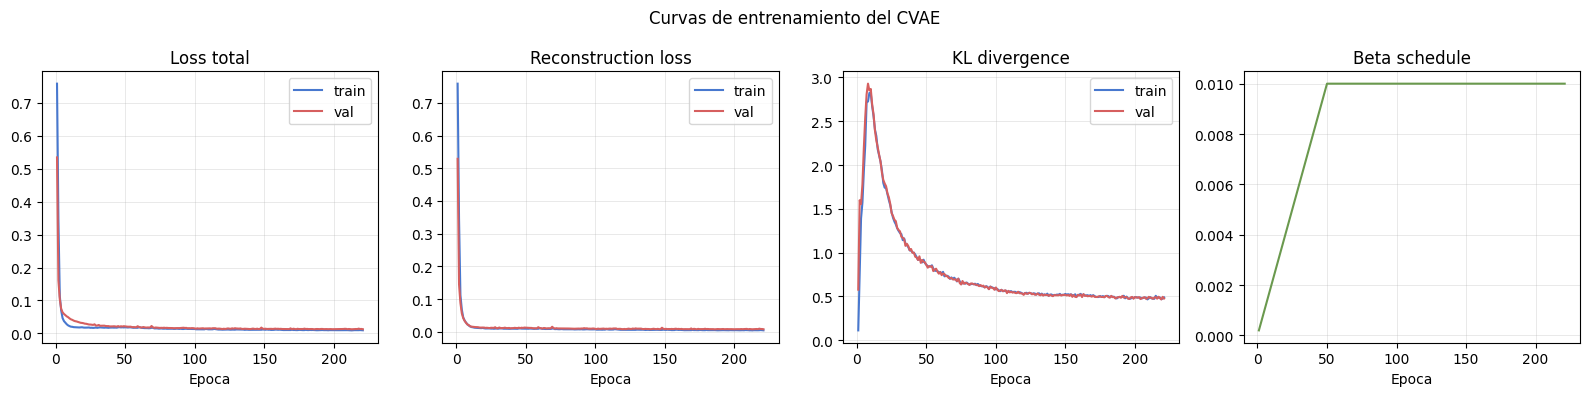

In [6]:
best_run = results["best_run"]
best_model = best_run["model"]
best_history = best_run["history"]
best_seed = best_run["seed"]

print(f"Mejor seed: {best_seed}")
print(f"Best epoch: {best_history['best_epoch']}")
print(f"Best val_total: {best_history['best_val_total']:.4f}")

plot_loss_curves(best_history)


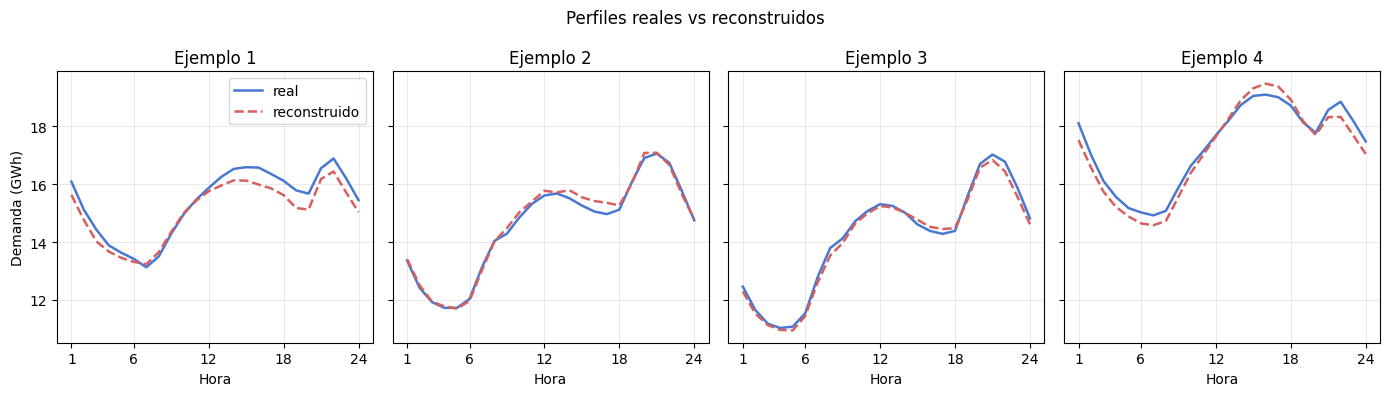

In [7]:
plot_reconstruction_vs_real(
    model=best_model,
    X=prepared["test"]["X"],
    C=prepared["test"]["C"],
    scaler_stats=preprocessing["x_scaler"],
    n_examples=4,
    device=device,
)


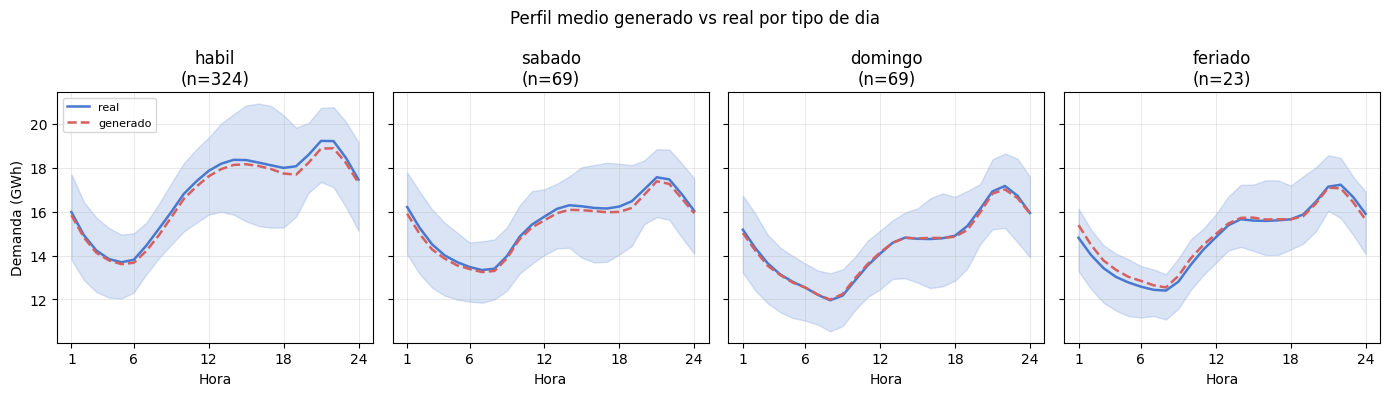

In [8]:
plot_generated_vs_real_by_condition(
    model=best_model,
    X=prepared["test"]["X"],
    C=prepared["test"]["C"],
    conditions=prepared["test"]["conditions"],
    scaler_stats=preprocessing["x_scaler"],
    device=device,
)


## 6. Guardado de artefactos

Se guarda el mejor modelo por validation loss junto con su configuracion, preprocesamiento y tablas de resultados. Las tablas tambien se exportan como CSV para el informe.


In [9]:
models_dir = project_root / "models"
results_dir = project_root / "results"
models_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)

model_path = models_dir / "cvae_baseline_final_cfull.pt"
configs_path = results_dir / "cvae_baseline_final_configs.csv"
losses_path = results_dir / "cvae_baseline_final_losses.csv"
metrics_path = results_dir / "cvae_baseline_final_metrics.csv"
metric_summary_path = results_dir / "cvae_baseline_final_metric_summary.csv"

torch.save(
    {
        "model_state_dict": best_model.state_dict(),
        "preprocessing": preprocessing,
        "hyperparams": HYPERPARAMS,
        "seeds": SEEDS,
        "best_seed": best_seed,
        "best_run_config": best_run["config"],
    },
    model_path,
)

configs.to_csv(configs_path, index=False)
losses.to_csv(losses_path, index=False)
metrics.to_csv(metrics_path, index=False)
metric_summary.to_csv(metric_summary_path, index=False)

print(f"Modelo guardado en: {model_path}")
print(f"Resultados guardados en: {results_dir}")


Modelo guardado en: /Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/models/cvae_baseline_final_cfull.pt
Resultados guardados en: /Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/results


## 7. Lectura metodologica

Este baseline queda como referencia final para comparar variantes posteriores. Una mejora futura deberia superar no solo la reconstruccion, sino tambien la calidad generativa: energia diaria, pico, hora pico, rampas, dispersion y perfiles medios por tipo de dia.


## 8. Resultados:

El baseline CVAE C-full logra reconstrucciones precisas y perfiles generados plausibles condicionados por calendario y clima. La pérdida KL se mantiene alejada de cero, por lo que el espacio latente no colapsa y el modelo conserva comportamiento variacional. La generación reproduce bien los perfiles medios por tipo de día, aunque presenta mayor error punto a punto que la reconstrucción y una ligera subestimación de la variabilidad real. Por lo tanto, este modelo queda como un baseline metodológicamente sólido, pero futuras variantes deberían enfocarse en mejorar diversidad, extremos y precisión generativa individual.